# TerraVista — Augmentation Probability Tuning (Validation Only)

This version fixes the earlier gap: the experiment **tunes the probability for each augmentation family**, rather than holding every probability at one assumed value.

## What is compared

A baseline plus seven one-factor-at-a-time sweeps are run: flips, rotation, colour jitter (including darkening), Gaussian blur, sensor noise, cutout, and background replacement. For each family, the tested probabilities are **0.10, 0.25, and 0.50**; every run uses the same seeds **42, 123, and 2026**. When testing one family, all other augmentation probabilities are zero. This isolates that family.

That is **22 configurations × 3 seeds = 66 full-training/full-validation runs**. Each candidate receives one screening epoch to keep the search feasible on Kaggle. The results report validation macro-F1 mean and sample standard deviation, paired same-seed differences against the baseline, and a recommended probability for each family. An observed winner is not treated as a demonstrated improvement when its paired mean gain does not exceed the seed-to-seed standard deviation.

The selected individual probabilities are then written to JSON so they can be used for the combined pipeline. Because separately optimal effects can interact when combined, the notebook includes an optional combined confirmation run (validation only).

## Runtime protections

- Restart the Kaggle session before running from the first cell. The first cell handles the known PyTorch/Triton import incompatibility before importing TorchVision.
- Model/optimizer and all augmentation branches are smoke-tested before the cache build.
- Train + validation images are decoded/resized once into a resumable cache; background masks are cached once for training images only. Both caches are visible under `/kaggle/working/terravista_probability_tuning/cache` and can resume if their partial files remain in the same session.
- The search saves a CSV after every completed (configuration, seed) run. Rerunning the search cell skips completed runs.
- Test image paths are never resolved; no test images or test metrics are used.

**Screening limitation:** one epoch is a quick probability screen, not proof of a fully converged optimum. If many top runs are near the best end-of-epoch score while still learning, increase `SCREEN_EPOCHS` equally for every candidate and repeat the complete sweep.


In [1]:
from pathlib import Path
import os, gc, json, time, math, random, hashlib, shutil, zipfile, copy, warnings
from typing import Literal, Union

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2
cv2.setNumThreads(1)
from tqdm.auto import tqdm
import sys, importlib, importlib.util

# --- Triton guard -----------------------------------------------------------------
# Kaggle's Python 3.13 image can ship a PyTorch/Triton pair that disagree, which crashes
# torch._dynamo (imported lazily by AdamW) with errors like
# "module 'triton.backends' has no attribute 'compiler'". This study never uses
# torch.compile, so Triton is not needed. Hiding it BEFORE torch is imported makes PyTorch
# take its normal "no Triton" path. Set TERRAVISTA_KEEP_TRITON=1 to disable this guard.
KEEP_TRITON = os.environ.get("TERRAVISTA_KEEP_TRITON", "").strip() == "1"
TRITON_HIDDEN = False
if not KEEP_TRITON:
    if "torch" in sys.modules:
        print("NOTE: torch was already imported in this session, so Triton cannot be hidden. "
              "If the check below fails, use Run > Restart session and run this cell first.")
    else:
        sys.modules["triton"] = None   # `import triton` now raises ImportError
        TRITON_HIDDEN = True

import torch

# Fail fast: import dynamo and build/step an optimizer now, not 20 minutes into training.
try:
    import torch._dynamo  # noqa: F401
    _probe = torch.nn.Parameter(torch.zeros(2))
    _probe.grad = torch.ones(2)
    torch.optim.AdamW([_probe], lr=1e-3).step()
    del _probe
except Exception as exc:
    raise RuntimeError(
        "PyTorch's optimizer/dynamo import failed. Use Run > Restart session, then run this "
        "first cell before any other cell. Original error: "
        f"{type(exc).__name__}: {exc}"
    ) from exc

import torchvision
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
)

# If running outside Kaggle, set these environment variables before starting Python:
# TERRAVISTA_SPLIT_CSV=/path/to/split.csv
# TERRAVISTA_COLOR_DIR=/path/to/PlantVillage/color
# TERRAVISTA_OUTPUT_DIR=/path/to/output
INPUT_ROOT = Path(os.environ.get("TERRAVISTA_INPUT_ROOT", "/kaggle/input"))
SPLIT_CSV_OVERRIDE = os.environ.get("TERRAVISTA_SPLIT_CSV", "").strip()
COLOR_DIR_OVERRIDE = os.environ.get("TERRAVISTA_COLOR_DIR", "").strip()
_default_out = "/kaggle/working/terravista_augmentation_validation_study" if Path("/kaggle/working").exists() else "./terravista_augmentation_validation_study"
BASE_OUTPUT_DIR = Path(os.environ.get("TERRAVISTA_OUTPUT_DIR", _default_out))
BASE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

STUDY_VERSION = "terravista-augmentation-probability-search-v3.0"
IMG_SIZE = 224
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
SEEDS = [42, 123, 2026]

# Every probability candidate is trained for one screening epoch, on the complete training split.
# One epoch keeps this initial sweep practical; ambiguous winners should be confirmed with equal longer runs.
SCREEN_EPOCHS = 1
assert SCREEN_EPOCHS >= 1, "SCREEN_EPOCHS must be a positive integer."
TRAIN_BATCH_SIZE = 32
EVAL_BATCH_SIZE = 64
NUM_WORKERS = 4
PREFETCH_FACTOR = 4
try:
    _shm_free_mib = shutil.disk_usage("/dev/shm").free / (1024 ** 2)
    if _shm_free_mib < 256:
        NUM_WORKERS, PREFETCH_FACTOR = 2, 2
    elif _shm_free_mib < 1024:
        PREFETCH_FACTOR = 2
except OSError:
    pass
USE_AMP = True
BACKBONE_LR = 1e-5
CLASSIFIER_LR = 5e-4
WEIGHT_DECAY = 1e-4

# Fixed transformation strengths. The experiment tunes the application probability for each family.
ROTATION_DEGREES = 15.0
BRIGHTNESS_RANGE = (0.60, 1.40)       # includes darkening, as required
CONTRAST_RANGE = (0.80, 1.20)
SATURATION_RANGE = (0.80, 1.20)
HUE_STRENGTH = 0.02                   # retained in config/report as a fixed small setting
SENSOR_NOISE_STD = 0.02
BLUR_KERNEL_SIZE = 5
CUTOUT_MIN_AREA = 0.02
CUTOUT_MAX_AREA = 0.15                # below the 20–25% maximum discussed
BACKGROUND_MASK_SIZE = 112
BACKGROUND_MASK_CACHE_VERSION = "grabcut-112px-3iter-v1"
BACKGROUND_PALETTE = [
    (166, 166, 158), (196, 181, 153), (151, 169, 178),
    (157, 169, 147), (210, 204, 188), (151, 139, 125),
]
PROBABILITY_VALUES = (0.10, 0.25, 0.50)
PROBABILITY_FAMILIES = [
    ("flip", "p_flip", "Horizontal and vertical flips"),
    ("rotation", "p_rotation", "Rotation up to ±15 degrees"),
    ("colour", "p_colour", "Brightness/darkening, contrast and saturation jitter"),
    ("blur", "p_blur", "Gaussian blur"),
    ("sensor_noise", "p_noise", "Gaussian sensor noise"),
    ("cutout", "p_cutout", "Cutout; maximum patch area 15%"),
    ("background", "p_background", "Synthetic background replacement using cached training masks"),
]
PROBABILITY_KEYS = [x[1] for x in PROBABILITY_FAMILIES]
BASE_PROBS = {key: 0.0 for key in PROBABILITY_KEYS}

CONFIGS = [{
    "name": "baseline_all_probabilities_zero",
    "family": "baseline",
    "tested_probability": 0.0,
    "description": "No random augmentation",
    **BASE_PROBS,
}]
for _family, _prob_key, _description in PROBABILITY_FAMILIES:
    for _probability in PROBABILITY_VALUES:
        _cfg = {
            "name": f"{_family}_p{int(round(_probability * 100)):02d}",
            "family": _family,
            "tested_probability": float(_probability),
            "description": _description,
            **BASE_PROBS,
        }
        _cfg[_prob_key] = float(_probability)
        CONFIGS.append(_cfg)
CONFIG_BY_NAME = {c["name"]: c for c in CONFIGS}

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type != "cuda":
    raise RuntimeError("This study is designed for a Kaggle GPU. In Kaggle, select Settings → Accelerator → GPU and rerun.")

# Fixed seeds and deterministic cuDNN settings improve reproducibility in the same runtime.
torch.set_num_threads(1)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
try:
    torch.set_float32_matmul_precision("high")
except Exception:
    pass

try:
    IN_NOTEBOOK = get_ipython() is not None
except NameError:
    IN_NOTEBOOK = False

def show_table(frame):
    if IN_NOTEBOOK:
        from IPython.display import display
        display(frame)
    else:
        print(frame.to_string(index=False))

print("Device:", DEVICE)
try:
    from importlib.metadata import version as _pkg_version
    _triton_version = _pkg_version("triton")
except Exception:
    _triton_version = "not installed"
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__,
      "| Triton:", "hidden (not used by this study)" if TRITON_HIDDEN else _triton_version)
print(f"Training settings: epochs={SCREEN_EPOCHS}, batch={TRAIN_BATCH_SIZE}, AMP={USE_AMP}, workers={NUM_WORKERS}")
print("Seeds:", SEEDS)
print("Output:", BASE_OUTPUT_DIR.resolve())


Device: cuda
PyTorch: 2.11.0+cu128 | torchvision: 0.26.0+cu128 | Triton: hidden (not used by this study)
Training settings: epochs=1, batch=32, AMP=True, workers=4
Seeds: [42, 123, 2026]
Output: /kaggle/working/terravista_augmentation_validation_study


## 1. Read the existing split — only train and validation are accessed

The manifest may contain test rows, but the notebook never creates a test dataframe or resolves test-image paths.

In [2]:
def _unique_paths(items):
    result = []
    seen = set()
    for item in items:
        p = Path(item).resolve()
        if p not in seen:
            seen.add(p)
            result.append(p)
    return result

if SPLIT_CSV_OVERRIDE:
    SPLIT_CSV = Path(SPLIT_CSV_OVERRIDE).expanduser().resolve()
    if not SPLIT_CSV.is_file():
        raise FileNotFoundError(f"TERRAVISTA_SPLIT_CSV does not exist: {SPLIT_CSV}")
else:
    split_candidates = _unique_paths(
        list(INPUT_ROOT.glob("datasets/*/*/split.csv"))
        + list(INPUT_ROOT.glob("*/*/split.csv"))
        + list(INPUT_ROOT.glob("*/split.csv"))
    )
    if not split_candidates:
        raise FileNotFoundError(
            "Could not find split.csv. Attach the split dataset or set TERRAVISTA_SPLIT_CSV."
        )
    if len(split_candidates) > 1:
        print("Found more than one split.csv:")
        for p in split_candidates:
            print(" -", p)
        raise RuntimeError("Set TERRAVISTA_SPLIT_CSV to the intended split.csv to avoid using the wrong manifest.")
    SPLIT_CSV = split_candidates[0]

splits_df = pd.read_csv(SPLIT_CSV)
required = {"path", "class", "split"}
if not required.issubset(splits_df.columns):
    raise ValueError(f"split.csv must contain columns {sorted(required)}; found {splits_df.columns.tolist()}")

splits_df["split"] = (
    splits_df["split"].astype(str).str.strip().str.lower()
    .replace({"validation": "val", "valid": "val"})
)

# Do not make a test dataframe and do not resolve any test paths.
train_df = splits_df.loc[splits_df["split"] == "train", ["path", "class", "split"]].copy().reset_index(drop=True)
val_df = splits_df.loc[splits_df["split"] == "val", ["path", "class", "split"]].copy().reset_index(drop=True)
if train_df.empty or val_df.empty:
    raise ValueError(f"Training/validation rows missing: train={len(train_df)}, val={len(val_df)}")


def normalize_relpath(value):
    value = str(value).replace("\\", "/").strip().lstrip("/")
    if value.lower().startswith("color/"):
        value = value[6:]
    return value

train_df["relative_path"] = train_df["path"].map(normalize_relpath)
val_df["relative_path"] = val_df["path"].map(normalize_relpath)

if COLOR_DIR_OVERRIDE:
    COLOR_DIR = Path(COLOR_DIR_OVERRIDE).expanduser().resolve()
    if not COLOR_DIR.is_dir():
        raise FileNotFoundError(f"TERRAVISTA_COLOR_DIR is not a folder: {COLOR_DIR}")
else:
    color_candidates = _unique_paths(
        [Path("/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color")]
        + list(INPUT_ROOT.glob("datasets/*/*/color"))
        + list(INPUT_ROOT.glob("*/*/color"))
        + list(INPUT_ROOT.glob("*/color"))
        + list(INPUT_ROOT.glob("datasets/*/*/*/color"))
        + list(INPUT_ROOT.glob("*/*/*/color"))
    )
    COLOR_DIR = None
    probe = train_df.iloc[0]["relative_path"]
    for candidate in color_candidates:
        if candidate.is_dir() and (candidate / probe).is_file():
            COLOR_DIR = candidate
            break
    if COLOR_DIR is None:
        raise FileNotFoundError(
            "Could not locate the PlantVillage colour image folder. Set TERRAVISTA_COLOR_DIR to its 'color' folder."
        )

train_df["resolved_image_path"] = train_df["relative_path"].map(lambda p: str(COLOR_DIR / p))
val_df["resolved_image_path"] = val_df["relative_path"].map(lambda p: str(COLOR_DIR / p))

# Validate only train/validation image paths.
for split_name, frame in [("train", train_df), ("val", val_df)]:
    exists = frame["resolved_image_path"].map(lambda p: Path(p).is_file())
    if not exists.all():
        print(frame.loc[~exists, ["path", "class"]].head(10).to_string(index=False))
        raise FileNotFoundError(f"Missing {int((~exists).sum())} {split_name} images under {COLOR_DIR}")

# Prevent duplicate paths and class mismatch in the data actually used.
train_val_relpaths = pd.concat([train_df["relative_path"], val_df["relative_path"]], ignore_index=True)
if train_val_relpaths.duplicated().any():
    raise ValueError("Duplicate path occurs in the train/validation split; ask the dataset owner to check the split.")
for split_name, frame in [("train", train_df), ("val", val_df)]:
    folder_label = frame["relative_path"].str.split("/").str[0]
    bad = folder_label != frame["class"].astype(str)
    if bad.any():
        show_table(frame.loc[bad, ["path", "class"]].head(10))
        raise ValueError(f"Found folder/class label mismatch in {split_name} rows.")

CLASS_NAMES = sorted(train_df["class"].astype(str).unique().tolist())
if sorted(val_df["class"].astype(str).unique().tolist()) != CLASS_NAMES:
    missing_in_val = sorted(set(CLASS_NAMES) - set(val_df["class"].astype(str)))
    missing_in_train = sorted(set(val_df["class"].astype(str)) - set(CLASS_NAMES))
    raise ValueError(f"Train/validation classes differ. Missing validation={missing_in_val}; extra validation={missing_in_train}")
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)

print("Split manifest:", SPLIT_CSV)
print("Image root:", COLOR_DIR)
print(f"Train images used: {len(train_df):,}")
print(f"Validation images used: {len(val_df):,}")
print("Classes:", NUM_CLASSES)
print("No test-image paths have been resolved or loaded.")
assert NUM_CLASSES == 38, f"This study expects the 38 PlantVillage classes; found {NUM_CLASSES}. Verify dataset and split." 


Split manifest: /kaggle/input/datasets/astitvasrivastava05/split-aug/split.csv
Image root: /kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color
Train images used: 37,751
Validation images used: 7,976
Classes: 38
No test-image paths have been resolved or loaded.


In [3]:
# Runtime preflight: verify pretrained weights, model construction and CUDA forward pass
# BEFORE spending time building the multi-gigabyte decoded image cache.
print("Preflight: loading the standard pretrained ResNet-50 weights...")
_WEIGHTS_PREFLIGHT = torchvision.models.ResNet50_Weights.DEFAULT
_preflight_model = torchvision.models.resnet50(weights=_WEIGHTS_PREFLIGHT).to(DEVICE).eval()
assert _preflight_model.fc.in_features == 2048, f"Unexpected ResNet-50 feature size: {_preflight_model.fc.in_features}"
with torch.inference_mode():
    _preflight_logits = _preflight_model(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE))
assert tuple(_preflight_logits.shape) == (1, 1000), f"Unexpected pretrained model output shape: {_preflight_logits.shape}"
_ = torch.optim.AdamW(_preflight_model.parameters(), lr=BACKBONE_LR, weight_decay=WEIGHT_DECAY)
print("Preflight passed: optimizer builds; ResNet-50 forward output shape", tuple(_preflight_logits.shape))
del _, _preflight_model, _preflight_logits, _WEIGHTS_PREFLIGHT
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
print("No training images have been decoded or cached yet.")


Preflight: loading the standard pretrained ResNet-50 weights...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 207MB/s]


Preflight passed: optimizer builds; ResNet-50 forward output shape (1, 1000)
No training images have been decoded or cached yet.


## 2. Define probability candidates and GPU augmentation transforms

Every run changes the probability for one family only. Colour jitter uses brightness 0.60–1.40, so darkening is included; cutout hides at most 15% of a patch; background replacement uses train-only cached masks.

In [4]:
def make_random_background_batch(batch_size,height,width,device):
    palette=torch.as_tensor(BACKGROUND_PALETTE,device=device,dtype=torch.float32)/255.0
    c1=palette[torch.randint(0,len(BACKGROUND_PALETTE),(batch_size,),device=device)]
    c2=palette[torch.randint(0,len(BACKGROUND_PALETTE),(batch_size,),device=device)]
    solid=c1[:,:,None,None].expand(-1,-1,height,width)
    vh=torch.linspace(0,1,height,device=device).view(1,1,height,1)
    vw=torch.linspace(0,1,width,device=device).view(1,1,1,width)
    vertical=c1[:,:,None,None]*(1-vh)+c2[:,:,None,None]*vh
    horizontal=c1[:,:,None,None]*(1-vw)+c2[:,:,None,None]*vw
    choose_v=torch.rand(batch_size,device=device)<0.5
    gradient=torch.where(choose_v[:,None,None,None],vertical.expand(-1,-1,height,width),horizontal.expand(-1,-1,height,width))
    low=F.interpolate(c1[:,:,None,None]+torch.randn((batch_size,3,max(4,height//18),max(4,width//18)),device=device)*0.04,size=(height,width),mode="bilinear",align_corners=False)
    texture=F.avg_pool2d(low,kernel_size=3,stride=1,padding=1)
    style=torch.randint(0,3,(batch_size,),device=device)
    return torch.where((style==0)[:,None,None,None],solid,torch.where((style==1)[:,None,None,None],gradient,texture)).clamp(0,1)



def rgb_to_hsv_batch(x):
    """Convert float RGB [B,3,H,W] in [0,1] to hue, saturation, value tensors."""
    maxc, maxidx = x.max(dim=1)
    minc = x.min(dim=1).values
    delta = maxc - minc
    r, g, b = x[:, 0], x[:, 1], x[:, 2]
    hue = torch.zeros_like(maxc)
    nz = delta > 1e-6
    mask = (maxidx == 0) & nz
    hue[mask] = ((g - b)[mask] / delta[mask]) % 6.0
    mask = (maxidx == 1) & nz
    hue[mask] = ((b - r)[mask] / delta[mask]) + 2.0
    mask = (maxidx == 2) & nz
    hue[mask] = ((r - g)[mask] / delta[mask]) + 4.0
    hue = (hue / 6.0) % 1.0
    saturation = torch.where(maxc > 1e-6, delta / maxc.clamp_min(1e-6), torch.zeros_like(maxc))
    return hue, saturation, maxc


def hsv_to_rgb_batch(h, s, v):
    """Convert hue/saturation/value tensors [B,H,W] to float RGB [B,3,H,W]."""
    h6 = (h * 6.0) % 6.0
    idx = torch.floor(h6).long() % 6
    f = h6 - torch.floor(h6)
    p = v * (1.0 - s)
    q = v * (1.0 - f * s)
    t = v * (1.0 - (1.0 - f) * s)
    choices = torch.stack([
        torch.stack([v, t, p], dim=1),
        torch.stack([q, v, p], dim=1),
        torch.stack([p, v, t], dim=1),
        torch.stack([p, q, v], dim=1),
        torch.stack([t, p, v], dim=1),
        torch.stack([v, p, q], dim=1),
    ], dim=1)  # [B,6,3,H,W]
    gather_idx = idx[:, None, None, :, :].expand(-1, 1, 3, -1, -1)
    return choices.gather(1, gather_idx).squeeze(1).clamp(0.0, 1.0)

def augment_batch_gpu(images_uint8,config,*,device,background_alpha_uint8=None):
    """Apply independently sampled per-image transforms using config['p_*'] probabilities."""
    device=torch.device(device)
    if images_uint8.ndim!=4 or images_uint8.shape[-1]!=3: raise ValueError(f"Expected [B,H,W,3], got {tuple(images_uint8.shape)}")
    x=images_uint8.to(device=device,non_blocking=True).permute(0,3,1,2).contiguous().float().div_(255.0)
    b,_,h,w=x.shape

    # Background replacement is composited before geometry, using a train-only cached mask.
    if config.get("p_background",0.0)>0:
        if background_alpha_uint8 is None: raise ValueError("Background probability > 0 requires cached training masks.")
        alpha=background_alpha_uint8.to(device=device,non_blocking=True).float().unsqueeze(1).div_(255.0)
        alpha=F.interpolate(alpha,size=(h,w),mode="bilinear",align_corners=False).clamp_(0,1)
        bg=make_random_background_batch(b,h,w,device)
        composite=x*alpha+bg*(1-alpha)
        selected=(torch.rand(b,device=device)<config["p_background"])
        x=torch.where(selected[:,None,None,None],composite,x)

    # Flips and rotation probabilities are controlled independently.
    p_flip=float(config.get("p_flip",0.0))
    if p_flip>0:
        flip_h=torch.rand(b,device=device)<p_flip; flip_v=torch.rand(b,device=device)<p_flip
        x=torch.where(flip_h[:,None,None,None],x.flip(-1),x)
        x=torch.where(flip_v[:,None,None,None],x.flip(-2),x)
    p_rot=float(config.get("p_rotation",0.0))
    if p_rot>0:
        apply_rot=torch.rand(b,device=device)<p_rot
        angle=(torch.rand(b,device=device)*2-1)*math.radians(ROTATION_DEGREES)
        angle=torch.where(apply_rot,angle,torch.zeros_like(angle))
        co,si=torch.cos(angle),torch.sin(angle)
        theta=torch.zeros((b,2,3),device=device,dtype=x.dtype)
        theta[:,0,0]=co; theta[:,0,1]=-si; theta[:,1,0]=si; theta[:,1,1]=co
        grid=F.affine_grid(theta,x.size(),align_corners=False)
        x=F.grid_sample(x,grid,mode="bilinear",padding_mode="border",align_corners=False)

    p_colour=float(config.get("p_colour",0.0))
    if p_colour>0:
        apply=(torch.rand(b,device=device)<p_colour)[:,None,None,None]
        brightness=torch.empty((b,1,1,1),device=device).uniform_(*BRIGHTNESS_RANGE)
        changed=x*brightness
        gray=0.2989*changed[:,0:1]+0.5870*changed[:,1:2]+0.1140*changed[:,2:3]
        gray_mean=gray.mean((2,3),keepdim=True)
        contrast=torch.empty((b,1,1,1),device=device).uniform_(*CONTRAST_RANGE)
        changed=(changed-gray_mean)*contrast+gray_mean
        gray=0.2989*changed[:,0:1]+0.5870*changed[:,1:2]+0.1140*changed[:,2:3]
        saturation=torch.empty((b,1,1,1),device=device).uniform_(*SATURATION_RANGE)
        changed=gray+(changed-gray)*saturation
        # Small hue jitter is also part of colour jitter. Darkening is represented by
        # brightness factors below 1.0 in BRIGHTNESS_RANGE.
        hh, ss, vv = rgb_to_hsv_batch(changed.clamp(0,1))
        hue_shift=torch.empty((b,1,1),device=device).uniform_(-HUE_STRENGTH,HUE_STRENGTH)
        changed=hsv_to_rgb_batch((hh+hue_shift)%1.0,ss,vv)
        x=torch.where(apply,changed.clamp(0,1),x)

    p_blur=float(config.get("p_blur",0.0))
    if p_blur>0:
        k=torch.tensor([1,4,6,4,1],device=device,dtype=x.dtype); k=k/k.sum()
        kernel=(k[:,None]*k[None,:]).view(1,1,5,5).expand(3,1,5,5).contiguous()
        blurred=F.conv2d(x,kernel,padding=2,groups=3)
        apply=(torch.rand(b,device=device)<p_blur)[:,None,None,None]
        x=torch.where(apply,blurred,x)

    p_noise=float(config.get("p_noise",0.0))
    if p_noise>0:
        apply=(torch.rand(b,device=device)<p_noise)[:,None,None,None]
        noisy=(x+torch.randn_like(x)*SENSOR_NOISE_STD).clamp(0,1)
        x=torch.where(apply,noisy,x)

    p_cut=float(config.get("p_cutout",0.0))
    if p_cut>0:
        chosen=torch.rand(b,device=device)<p_cut
        area=torch.empty(b,device=device).uniform_(CUTOUT_MIN_AREA,CUTOUT_MAX_AREA)
        ratio=torch.empty(b,device=device).uniform_(math.log(0.5),math.log(2.0)).exp()
        ph=torch.sqrt(area*h*w*ratio).floor().long().clamp_(1,h)
        pw=torch.sqrt(area*h*w/ratio).floor().long().clamp_(1,w)
        top=(torch.rand(b,device=device)*(h-ph+1)).floor().long()
        left=(torch.rand(b,device=device)*(w-pw+1)).floor().long()
        yy=torch.arange(h,device=device).view(1,h,1); xx=torch.arange(w,device=device).view(1,1,w)
        mask=chosen[:,None,None]&(yy>=top[:,None,None])&(yy<(top+ph)[:,None,None])&(xx>=left[:,None,None])&(xx<(left+pw)[:,None,None])
        fill=x.mean((2,3),keepdim=True)
        x=torch.where(mask[:,None,:,:],fill,x)

    mean=torch.as_tensor(IMAGENET_MEAN,device=device,dtype=x.dtype).view(1,3,1,1)
    std=torch.as_tensor(IMAGENET_STD,device=device,dtype=x.dtype).view(1,3,1,1)
    return (x-mean)/std


In [5]:
# Fast smoke test before the large cache. Uses synthetic data only.
_smoke=torch.randint(0,256,(3,48,48,3),dtype=torch.uint8)
_smoke_mask=torch.full((3,BACKGROUND_MASK_SIZE,BACKGROUND_MASK_SIZE),255,dtype=torch.uint8)
_smoke_mask[:,12:100,12:100]=0
for _cfg in CONFIGS:
    _kw={"background_alpha_uint8":_smoke_mask} if _cfg["p_background"]>0 else {}
    _out=augment_batch_gpu(_smoke,_cfg,device=DEVICE,**_kw)
    assert _out.shape==(3,3,48,48) and torch.isfinite(_out).all(),_cfg["name"]
print(f"Passed all {len(CONFIGS)} augmentation/configuration smoke tests before cache creation.")
del _smoke,_smoke_mask,_out
if DEVICE.type=="cuda": torch.cuda.empty_cache()


Passed all 22 augmentation/configuration smoke tests before cache creation.


## 3. Decode and cache train + validation images once

At 224×224 RGB uint8 this is about 6.4 GiB. The cache is resumable; if a compatible prior-version cache is attached through Add Input, the notebook can reuse it.

In [6]:
from concurrent.futures import ThreadPoolExecutor

train_val_df = pd.concat([train_df, val_df], ignore_index=True)
cache_digest_source = (
    train_val_df["split"].astype(str) + "\t" + train_val_df["relative_path"].astype(str)
    + "\t" + train_val_df["class"].astype(str)
).str.cat(sep="\n")
CACHE_FINGERPRINT = hashlib.sha256(f"{IMG_SIZE}\n{cache_digest_source}".encode("utf-8")).hexdigest()
_cache_override = os.environ.get("TERRAVISTA_CACHE_DIR", "").strip()
if _cache_override:
    CACHE_DIR = Path(_cache_override).expanduser()
else:
    CACHE_DIR = BASE_OUTPUT_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
print("Cache directory:", CACHE_DIR)
CACHE_PATH = CACHE_DIR / f"plantvillage_train_val_{IMG_SIZE}_{CACHE_FINGERPRINT[:12]}.npy"
CACHE_EXTERNAL = False

# If an earlier notebook version's output has been attached through Add Input, reuse its exact cache
# file directly instead of copying 6.4 GiB. Prune image leaf folders to avoid walking the full dataset.
def find_attached_file(filename):
    if not INPUT_ROOT.exists():
        return None
    for root, dirs, files in os.walk(INPUT_ROOT):
        dirs[:] = [d for d in dirs if d.lower() not in {"color", "grayscale", "segmented"}]
        if filename in files:
            candidate = Path(root) / filename
            if candidate.is_file():
                return candidate
    return None

if not CACHE_PATH.is_file():
    _attached_cache = find_attached_file(CACHE_PATH.name)
    if _attached_cache is not None:
        CACHE_PATH = _attached_cache
        CACHE_EXTERNAL = True
        print("Reusing attached prior-version image cache read-only:", CACHE_PATH)
CACHE_META_PATH = CACHE_PATH.with_suffix(".json")
CACHE_PARTIAL_PATH = CACHE_PATH.with_name(CACHE_PATH.stem + ".partial.npy")
CACHE_PROGRESS_PATH = CACHE_PATH.with_name(CACHE_PATH.stem + ".progress.npy")
CACHE_SHAPE = (len(train_val_df), IMG_SIZE, IMG_SIZE, 3)
CACHE_ESTIMATED_BYTES = int(np.prod(CACHE_SHAPE))
CACHE_WORKERS = max(2, min(8, os.cpu_count() or 4, int(os.environ.get("TERRAVISTA_CACHE_WORKERS", "8"))))
CACHE_CHUNK_SIZE = max(64, CACHE_WORKERS * 32)


def _decode_resize_cache_item(item):
    """Thread worker: open and resize one RGB image; return (row index, uint8 array)."""
    row_index, image_path = item
    resampling = Image.Resampling.BILINEAR if hasattr(Image, "Resampling") else Image.BILINEAR
    try:
        with Image.open(image_path) as src:
            rgb = src.convert("RGB").resize((IMG_SIZE, IMG_SIZE), resampling)
            arr = np.asarray(rgb, dtype=np.uint8)
        if arr.shape != (IMG_SIZE, IMG_SIZE, 3):
            raise ValueError(f"Unexpected resized shape {arr.shape}")
        return int(row_index), arr
    except Exception as exc:
        raise RuntimeError(f"Failed to decode image at row {row_index}: {image_path}") from exc


cache_is_valid = False
if CACHE_PATH.is_file():
    try:
        cached = np.load(CACHE_PATH, mmap_mode="r")
        shape_and_dtype_ok = tuple(cached.shape) == CACHE_SHAPE and cached.dtype == np.uint8
        if CACHE_META_PATH.is_file():
            cache_meta = json.loads(CACHE_META_PATH.read_text())
            cache_is_valid = (
                cache_meta.get("fingerprint") == CACHE_FINGERPRINT and shape_and_dtype_ok
            )
        else:
            # The final filename contains this data/split fingerprint. Promotion only
            # happens after every row is written, so a complete final .npy without its
            # sidecar is recoverable after an interruption between the two file moves.
            cache_is_valid = shape_and_dtype_ok
            if cache_is_valid and not CACHE_EXTERNAL:
                CACHE_META_PATH.write_text(json.dumps({
                    "fingerprint": CACHE_FINGERPRINT,
                    "shape": CACHE_SHAPE,
                    "dtype": "uint8",
                    "image_size": IMG_SIZE,
                    "rows": len(train_val_df),
                    "source": "train + validation rows only",
                    "recovered_metadata": True,
                }, indent=2))
        del cached
    except Exception:
        cache_is_valid = False

if cache_is_valid:
    print("Reusing complete decoded image cache:", CACHE_PATH)
else:
    if CACHE_EXTERNAL:
        raise RuntimeError("An attached prior-version cache was found but its shape/metadata do not match this split. Detach it or use the matching split.")
    # Reuse incomplete work after a cell error or runtime interruption. A row is
    # marked done only after the resized bytes have been written to the memmap.
    partial_valid = False
    if CACHE_PARTIAL_PATH.is_file() and CACHE_PROGRESS_PATH.is_file():
        try:
            partial = np.load(CACHE_PARTIAL_PATH, mmap_mode="r+")
            progress = np.load(CACHE_PROGRESS_PATH, mmap_mode="r+")
            partial_valid = (
                tuple(partial.shape) == CACHE_SHAPE
                and partial.dtype == np.uint8
                and tuple(progress.shape) == (CACHE_SHAPE[0],)
                and progress.dtype == np.uint8
            )
            if partial_valid:
                cache = partial
                done = progress
            else:
                del partial, progress
        except Exception:
            partial_valid = False

    if not partial_valid:
        CACHE_PARTIAL_PATH.unlink(missing_ok=True)
        CACHE_PROGRESS_PATH.unlink(missing_ok=True)
        free_bytes = shutil.disk_usage(CACHE_DIR).free
        required_bytes = CACHE_ESTIMATED_BYTES + 256 * 1024 * 1024
        if free_bytes < required_bytes:
            raise OSError(
                f"Not enough free working storage for the image cache. Need about "
                f"{CACHE_ESTIMATED_BYTES / (1024**3):.2f} GiB plus a safety margin; "
                f"free={free_bytes / (1024**3):.2f} GiB. Set TERRAVISTA_OUTPUT_DIR "
                "to a drive with more space."
            )
        print(f"Starting cache build: {len(train_val_df):,} train/validation images; "
              f"estimated cache size {CACHE_ESTIMATED_BYTES / (1024**3):.2f} GiB.")
        cache = np.lib.format.open_memmap(
            CACHE_PARTIAL_PATH, mode="w+", dtype=np.uint8, shape=CACHE_SHAPE
        )
        done = np.lib.format.open_memmap(
            CACHE_PROGRESS_PATH, mode="w+", dtype=np.uint8, shape=(CACHE_SHAPE[0],)
        )
        done[:] = 0
        cache.flush()
        done.flush()

    completed_before = int(np.asarray(done).sum())
    remaining = np.flatnonzero(np.asarray(done) == 0)
    print(f"Cache workers: {CACHE_WORKERS}; chunk size: {CACHE_CHUNK_SIZE}; "
          f"resuming {completed_before:,}/{len(train_val_df):,} cached rows.")
    paths = train_val_df["resolved_image_path"].astype(str).to_numpy()
    progress_bar = tqdm(total=len(train_val_df), initial=completed_before,
                        desc="Parallel decode + resize", mininterval=2)
    try:
        with ThreadPoolExecutor(max_workers=CACHE_WORKERS) as pool:
            for start in range(0, len(remaining), CACHE_CHUNK_SIZE):
                indices = remaining[start:start + CACHE_CHUNK_SIZE]
                tasks = [(int(i), paths[int(i)]) for i in indices]
                for row_index, arr in pool.map(_decode_resize_cache_item, tasks):
                    cache[row_index] = arr
                    done[row_index] = 1
                # Frequent flushes make the cache resumable without losing a full pass.
                cache.flush()
                done.flush()
                progress_bar.update(len(indices))
    except Exception:
        cache.flush()
        done.flush()
        progress_bar.close()
        del cache, done
        raise
    progress_bar.close()
    cache.flush()
    done.flush()
    if int(np.asarray(done).sum()) != len(train_val_df):
        raise RuntimeError("Cache build did not finish all train/validation rows; rerun this cell to resume.")
    del cache, done

    # Write metadata before promotion. If the process is interrupted, the partial
    # array and row bitmap remain available for resuming.
    meta_tmp = CACHE_META_PATH.with_name(CACHE_META_PATH.name + ".tmp")
    meta_tmp.write_text(json.dumps({
        "fingerprint": CACHE_FINGERPRINT,
        "shape": CACHE_SHAPE,
        "dtype": "uint8",
        "image_size": IMG_SIZE,
        "rows": len(train_val_df),
        "source": "train + validation rows only",
        "cache_workers": CACHE_WORKERS,
    }, indent=2))
    os.replace(CACHE_PARTIAL_PATH, CACHE_PATH)
    os.replace(meta_tmp, CACHE_META_PATH)
    CACHE_PROGRESS_PATH.unlink(missing_ok=True)
    print("Saved complete cache:", CACHE_PATH)

TRAIN_POSITIONS = np.arange(len(train_df), dtype=np.int64)
VAL_POSITIONS = np.arange(len(train_df), len(train_df) + len(val_df), dtype=np.int64)
TRAIN_LABEL_IDS = train_df["class"].astype(str).map(CLASS_TO_IDX).to_numpy(dtype=np.int64)
VAL_LABEL_IDS = val_df["class"].astype(str).map(CLASS_TO_IDX).to_numpy(dtype=np.int64)
print("Cache ready. Train/validation rows:", len(TRAIN_POSITIONS), "/", len(VAL_POSITIONS))
print("Only training and validation image paths are used; no test images or test metrics are loaded.")


Cache directory: /kaggle/working/terravista_augmentation_validation_study/cache
Starting cache build: 45,727 train/validation images; estimated cache size 6.41 GiB.
Cache workers: 4; chunk size: 128; resuming 0/45,727 cached rows.


Parallel decode + resize:   0%|          | 0/45727 [00:00<?, ?it/s]

Saved complete cache: /kaggle/working/terravista_augmentation_validation_study/cache/plantvillage_train_val_224_9fb74edc1aef.npy
Cache ready. Train/validation rows: 37751 / 7976
Only training and validation image paths are used; no test images or test metrics are loaded.


## 4. Cache foreground masks for training images only

Mask estimation is done once, not in each batch. Inspect the preview and check how many masks fell back to all-foreground.

Training-only background masks: 37,751; workers=4; resuming 0/37,751.


GrabCut masks (training only):   0%|          | 0/37751 [00:00<?, ?it/s]

Saved training-only mask cache: /kaggle/working/terravista_augmentation_validation_study/cache/foreground_alpha_train_112_c95c6139a9c9.npy


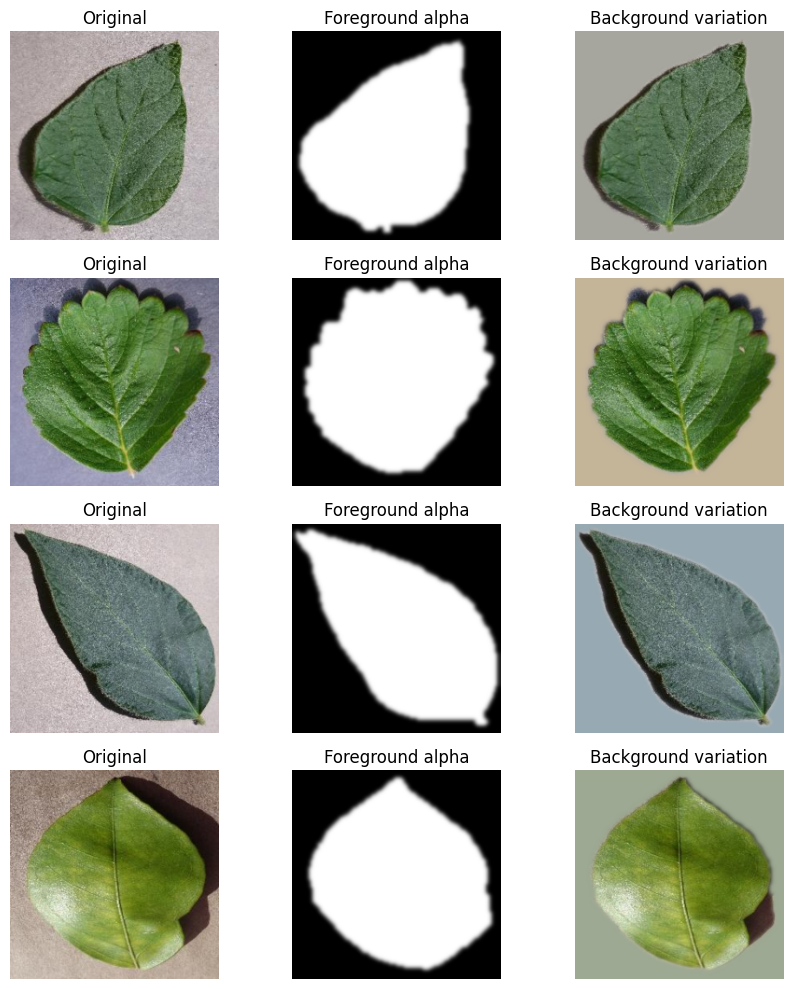

Background mask cache ready. Masks are generated for training images only.


In [7]:
MASK_CACHE_FINGERPRINT = hashlib.sha256(
    f"{CACHE_FINGERPRINT}\n{BACKGROUND_MASK_CACHE_VERSION}\n{BACKGROUND_MASK_SIZE}".encode("utf-8")
).hexdigest()
MASK_CACHE_PATH = CACHE_DIR / f"foreground_alpha_train_{BACKGROUND_MASK_SIZE}_{MASK_CACHE_FINGERPRINT[:12]}.npy"
MASK_META_PATH = MASK_CACHE_PATH.with_suffix(".json")
MASK_PARTIAL_PATH = MASK_CACHE_PATH.with_name(MASK_CACHE_PATH.stem + ".partial.npy")
MASK_PROGRESS_PATH = MASK_CACHE_PATH.with_name(MASK_CACHE_PATH.stem + ".progress.npy")
MASK_SHAPE = (len(train_df), BACKGROUND_MASK_SIZE, BACKGROUND_MASK_SIZE)
MASK_EXTERNAL = False
if not MASK_CACHE_PATH.is_file():
    _attached_masks = find_attached_file(MASK_CACHE_PATH.name)
    if _attached_masks is not None:
        MASK_CACHE_PATH = _attached_masks
        MASK_EXTERNAL = True
        print("Reusing attached prior-version training mask cache read-only:", MASK_CACHE_PATH)


def estimate_foreground_alpha_from_rgb(rgb_uint8, output_size=BACKGROUND_MASK_SIZE):
    """Return alpha uint8 (255=preserve plant, 0=replace background) and mask-valid flag."""
    small = cv2.resize(rgb_uint8, (output_size, output_size), interpolation=cv2.INTER_AREA)
    h, w = small.shape[:2]
    if h < 24 or w < 24:
        return np.full((output_size, output_size), 255, np.uint8), False
    bgr = cv2.cvtColor(small, cv2.COLOR_RGB2BGR)
    mask = np.full((h, w), cv2.GC_PR_FGD, dtype=np.uint8)
    border = max(1, round(min(h, w) * 0.015))
    mask[:border, :] = cv2.GC_BGD; mask[-border:, :] = cv2.GC_BGD
    mask[:, :border] = cv2.GC_BGD; mask[:, -border:] = cv2.GC_BGD
    cv2.ellipse(mask, (w//2, h//2), (max(5, int(w*0.15)), max(5, int(h*0.22))), 0, 0, 360, cv2.GC_FGD, -1)
    bg_model = np.zeros((1, 65), np.float64); fg_model = np.zeros((1, 65), np.float64)
    try:
        cv2.grabCut(bgr, mask, None, bg_model, fg_model, iterCount=3, mode=cv2.GC_INIT_WITH_MASK)
    except cv2.error:
        return np.full((output_size, output_size), 255, np.uint8), False
    fg = np.isin(mask, (cv2.GC_FGD, cv2.GC_PR_FGD)).astype(np.uint8)
    frac = float(fg.mean())
    if not 0.08 <= frac <= 0.92:
        return np.full((output_size, output_size), 255, np.uint8), False
    fg = cv2.morphologyEx(fg, cv2.MORPH_CLOSE, np.ones((3,3), np.uint8), iterations=1)
    alpha = cv2.GaussianBlur(fg.astype(np.float32), (0,0), sigmaX=1.0)
    return np.round(np.clip(alpha,0,1)*255).astype(np.uint8), True

mask_valid=False
if MASK_CACHE_PATH.is_file():
    try:
        _m=np.load(MASK_CACHE_PATH,mmap_mode="r")
        _shape_ok=tuple(_m.shape)==MASK_SHAPE and _m.dtype==np.uint8
        if MASK_META_PATH.is_file():
            _meta=json.loads(MASK_META_PATH.read_text())
            mask_valid=_meta.get("fingerprint")==MASK_CACHE_FINGERPRINT and _shape_ok
        else:
            mask_valid=_shape_ok
            if mask_valid and not MASK_EXTERNAL:
                MASK_META_PATH.write_text(json.dumps({"fingerprint":MASK_CACHE_FINGERPRINT,"shape":MASK_SHAPE,"dtype":"uint8"},indent=2))
        del _m
    except Exception:
        mask_valid=False
if mask_valid:
    print("Reusing complete training-only mask cache:", MASK_CACHE_PATH)
else:
    if MASK_EXTERNAL:
        raise RuntimeError("Attached background-mask cache shape/fingerprint does not match this split. Detach it or use a matching manifest.")
    _partial_valid=False
    if MASK_PARTIAL_PATH.is_file() and MASK_PROGRESS_PATH.is_file():
        try:
            _pm=np.load(MASK_PARTIAL_PATH,mmap_mode="r+"); _pd=np.load(MASK_PROGRESS_PATH,mmap_mode="r+")
            _partial_valid=tuple(_pm.shape)==MASK_SHAPE and _pm.dtype==np.uint8 and tuple(_pd.shape)==(len(train_df),) and _pd.dtype==np.uint8
            if _partial_valid: _mask_cache,_mask_done=_pm,_pd
            else: del _pm,_pd
        except Exception: _partial_valid=False
    if not _partial_valid:
        MASK_PARTIAL_PATH.unlink(missing_ok=True); MASK_PROGRESS_PATH.unlink(missing_ok=True)
        _free=shutil.disk_usage(CACHE_DIR).free
        _needed=int(np.prod(MASK_SHAPE))+128*1024*1024
        if _free < _needed: raise OSError(f"Insufficient space for training mask cache ({np.prod(MASK_SHAPE)/(1024**3):.2f} GiB plus margin).")
        _mask_cache=np.lib.format.open_memmap(MASK_PARTIAL_PATH,mode="w+",dtype=np.uint8,shape=MASK_SHAPE)
        _mask_done=np.lib.format.open_memmap(MASK_PROGRESS_PATH,mode="w+",dtype=np.uint8,shape=(len(train_df),))
        _mask_cache[:]=255; _mask_done[:]=0; _mask_cache.flush(); _mask_done.flush()
    _rgb_cache=np.load(CACHE_PATH,mmap_mode="r")
    _remaining=np.flatnonzero(np.asarray(_mask_done)==0)
    _mask_workers=max(2,min(8,os.cpu_count() or 4,int(os.environ.get("TERRAVISTA_CACHE_WORKERS","4"))))
    print(f"Training-only background masks: {len(train_df):,}; workers={_mask_workers}; resuming {int(np.asarray(_mask_done).sum()):,}/{len(train_df):,}.")
    def _mask_task(i):
        a,_ok=estimate_foreground_alpha_from_rgb(np.asarray(_rgb_cache[int(i)]))
        return int(i),a
    _bar=tqdm(total=len(train_df),initial=int(np.asarray(_mask_done).sum()),desc="GrabCut masks (training only)",mininterval=2)
    try:
        with ThreadPoolExecutor(max_workers=_mask_workers) as _pool:
            _chunk=max(32,_mask_workers*8)
            for _st in range(0,len(_remaining),_chunk):
                _ids=_remaining[_st:_st+_chunk]
                for _i,_a in _pool.map(_mask_task,_ids):
                    _mask_cache[_i]=_a; _mask_done[_i]=1
                _mask_cache.flush(); _mask_done.flush(); _bar.update(len(_ids))
    except Exception:
        _mask_cache.flush(); _mask_done.flush(); _bar.close(); del _mask_cache,_mask_done,_rgb_cache; raise
    _bar.close(); _mask_cache.flush(); _mask_done.flush()
    if int(np.asarray(_mask_done).sum()) != len(train_df):
        del _mask_cache,_mask_done,_rgb_cache
        raise RuntimeError("Background mask cache incomplete; rerun this cell to resume.")
    del _mask_cache,_mask_done,_rgb_cache
    _tmp_meta=MASK_META_PATH.with_name(MASK_META_PATH.name+".tmp")
    _tmp_meta.write_text(json.dumps({"fingerprint":MASK_CACHE_FINGERPRINT,"shape":MASK_SHAPE,"dtype":"uint8","mask_size":BACKGROUND_MASK_SIZE,"rows":len(train_df),"algorithm":BACKGROUND_MASK_CACHE_VERSION},indent=2))
    os.replace(MASK_PARTIAL_PATH,MASK_CACHE_PATH); os.replace(_tmp_meta,MASK_META_PATH); MASK_PROGRESS_PATH.unlink(missing_ok=True)
    print("Saved training-only mask cache:",MASK_CACHE_PATH)

# Quick visual spot-check using training images only.
_mask_preview=np.load(MASK_CACHE_PATH,mmap_mode="r")
_preview_ids=np.linspace(0,len(train_df)-1,min(4,len(train_df)),dtype=int)
_fig,_axes=plt.subplots(len(_preview_ids),3,figsize=(9,2.5*len(_preview_ids)))
if len(_preview_ids)==1: _axes=np.expand_dims(_axes,0)
for _i,_idx in enumerate(_preview_ids):
    _rgb=np.asarray(np.load(CACHE_PATH,mmap_mode="r")[_idx])
    _alpha=cv2.resize(np.asarray(_mask_preview[_idx]),(IMG_SIZE,IMG_SIZE),interpolation=cv2.INTER_LINEAR)
    _colour=np.asarray(BACKGROUND_PALETTE[_i%len(BACKGROUND_PALETTE)],dtype=np.uint8)
    _bg=np.broadcast_to(_colour[None,None,:],_rgb.shape)
    _a=_alpha[...,None].astype(np.float32)/255
    _comp=(_rgb.astype(np.float32)*_a+_bg.astype(np.float32)*(1-_a)).clip(0,255).astype(np.uint8)
    _axes[_i,0].imshow(_rgb); _axes[_i,0].set_title("Original")
    _axes[_i,1].imshow(_alpha,cmap="gray",vmin=0,vmax=255); _axes[_i,1].set_title("Foreground alpha")
    _axes[_i,2].imshow(_comp); _axes[_i,2].set_title("Background variation")
    for _ax in _axes[_i]: _ax.axis("off")
_fig.tight_layout()
if IN_NOTEBOOK: plt.show()
plt.close(_fig)
print("Background mask cache ready. Masks are generated for training images only.")
del _mask_preview


## 5. Before/after visual check for every augmentation family

This grid uses a few **training** images only and applies each transform with probability 1.0 for visibility. It is a visual sanity check, not part of the probability search (which tests 0.10, 0.25 and 0.50). Inspect the background masks carefully; a bad mask can remove leaf tissue or lesions.

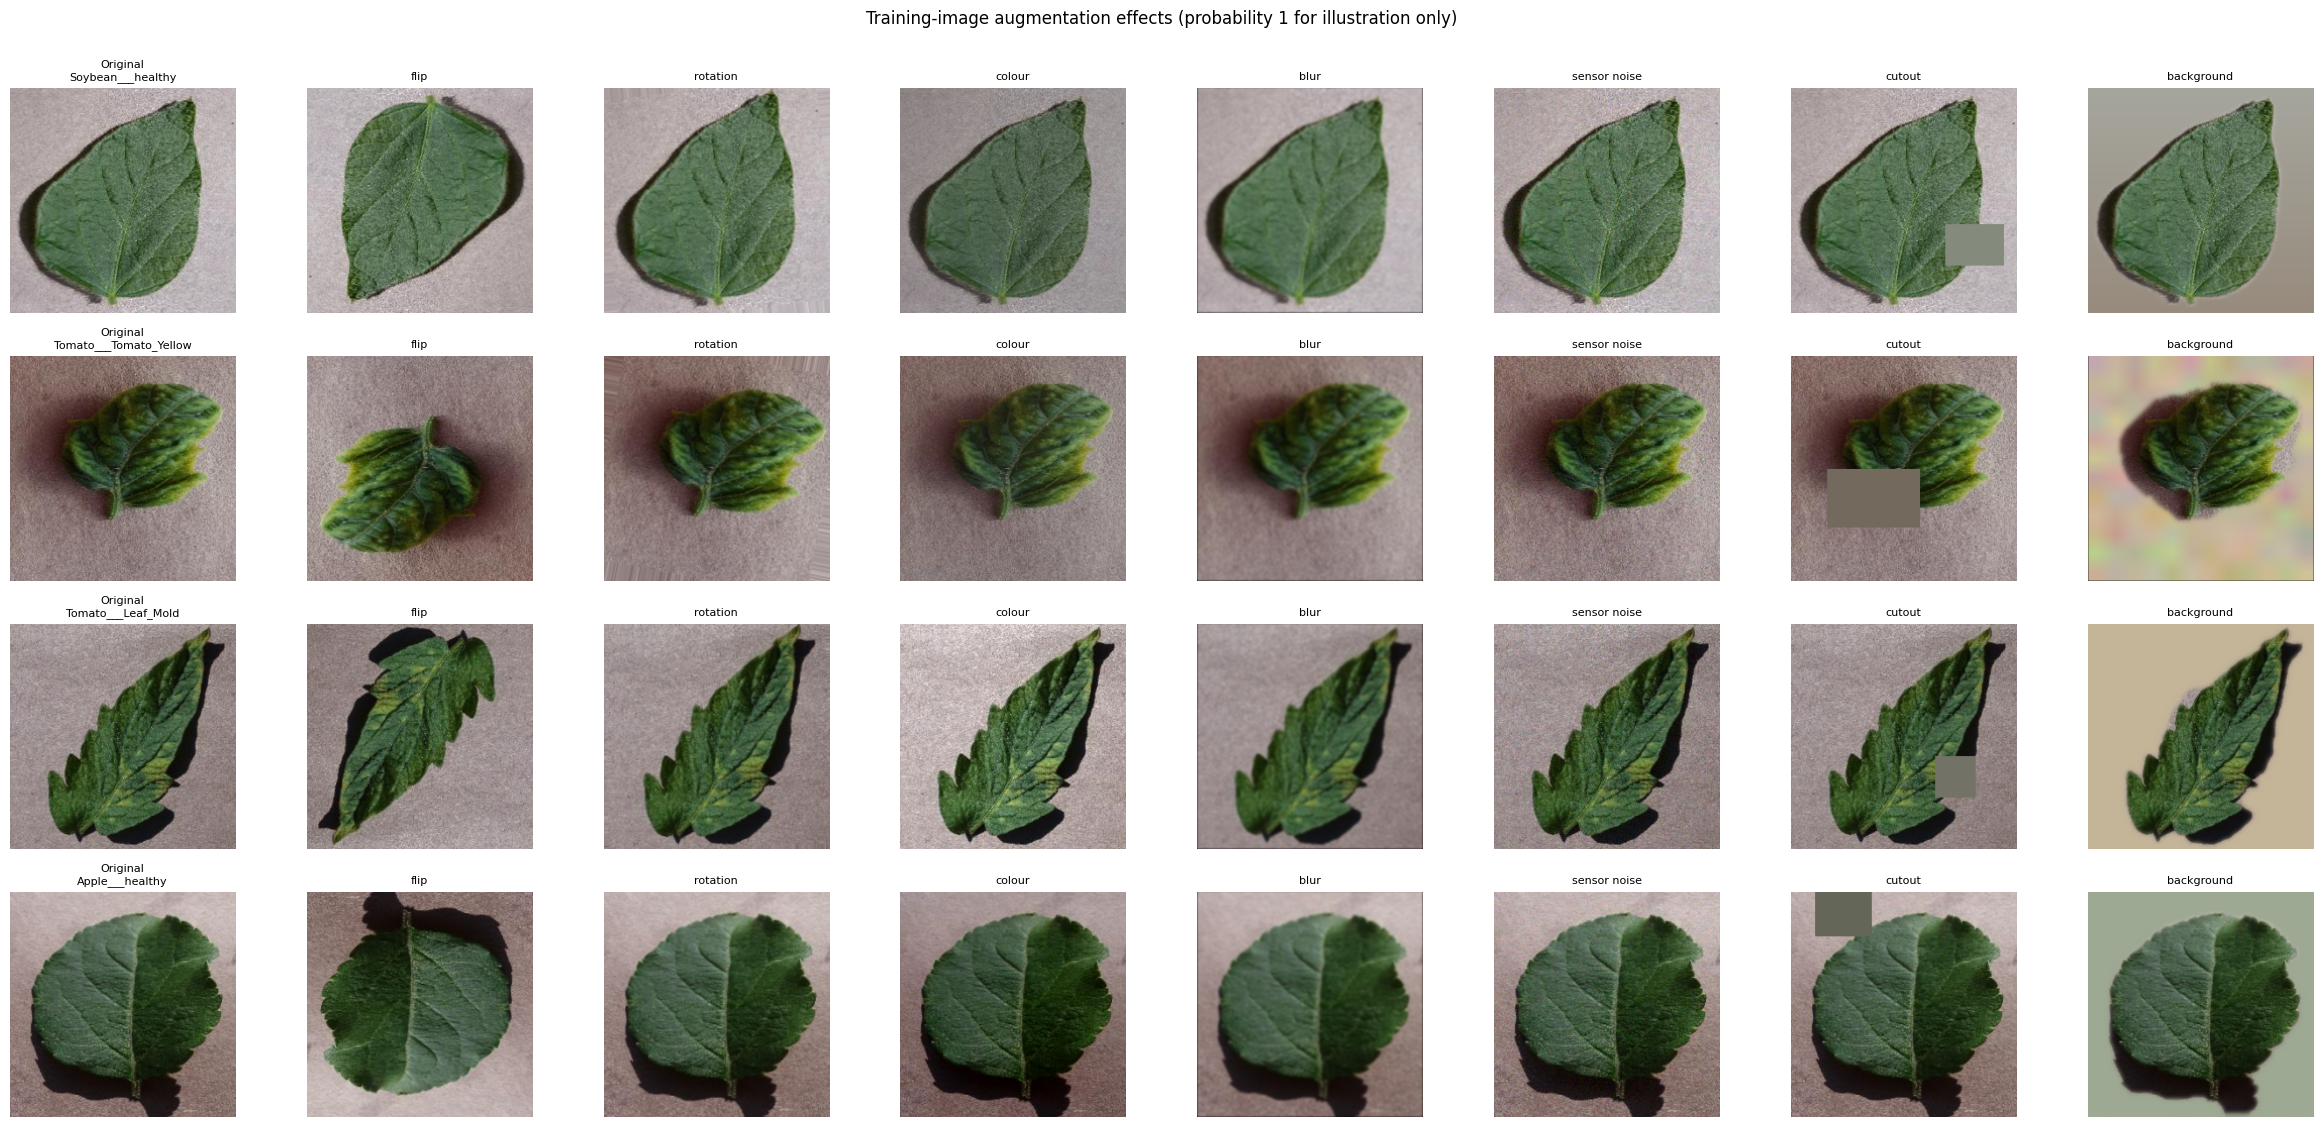

Saved visual sanity check: /kaggle/working/terravista_augmentation_validation_study/augmentation_probability_visual_check.png
Review the background column for leaf/lesion damage before interpreting its validation score.


In [8]:
# Visual showcase: four training images x eight columns. This does not use validation/test images.
_rgb_cache_preview=np.load(CACHE_PATH,mmap_mode="r")
_mask_cache_preview=np.load(MASK_CACHE_PATH,mmap_mode="r")
# Choose up to four distinct classes with a training example.
_sample_ids=[]
for _cls in train_df["class"].astype(str).drop_duplicates().tolist():
    _matches=np.flatnonzero(train_df["class"].astype(str).to_numpy()==_cls)
    if len(_matches): _sample_ids.append(int(_matches[0]))
    if len(_sample_ids)>=4: break
if not _sample_ids: _sample_ids=[0]
_preview_families=[("Original",None,None)]+[(fam,prob_key,desc) for fam,prob_key,desc in PROBABILITY_FAMILIES]
_preview_configs=[]
for _family,_prob_key,_desc in _preview_families[1:]:
    _cfg={"name":f"preview_{_family}","family":_family,"tested_probability":1.0,"description":_desc,**BASE_PROBS}
    _cfg[_prob_key]=1.0
    _preview_configs.append((_family,_cfg))

torch.manual_seed(SEEDS[0]); np.random.seed(SEEDS[0])
_fig,_axes=plt.subplots(len(_sample_ids),len(_preview_families),figsize=(3.0*len(_preview_families),2.8*len(_sample_ids)))
if len(_sample_ids)==1: _axes=np.expand_dims(_axes,0)
_mean=torch.tensor(IMAGENET_MEAN,device=DEVICE).view(1,3,1,1)
_std=torch.tensor(IMAGENET_STD,device=DEVICE).view(1,3,1,1)
for _ri,_idx in enumerate(_sample_ids):
    _original=np.asarray(_rgb_cache_preview[_idx])
    _axes[_ri,0].imshow(_original); _axes[_ri,0].set_title(f"Original\n{train_df.iloc[_idx]['class'][:22]}",fontsize=8); _axes[_ri,0].axis("off")
    for _ci,(_fam,_cfg) in enumerate(_preview_configs,start=1):
        _alpha_tensor=None
        if _fam=="background":
            _alpha_tensor=torch.from_numpy(np.array(_mask_cache_preview[_idx],copy=True)[None])
        _out=augment_batch_gpu(torch.from_numpy(np.array(_original,copy=True)[None]),_cfg,device=DEVICE,background_alpha_uint8=_alpha_tensor)
        _shown=(_out*_std+_mean).clamp(0,1)[0].permute(1,2,0).detach().cpu().numpy()
        _axes[_ri,_ci].imshow(_shown)
        _axes[_ri,_ci].set_title(_fam.replace("_"," "),fontsize=8)
        _axes[_ri,_ci].axis("off")
_fig.suptitle("Training-image augmentation effects (probability 1 for illustration only)",y=1.002)
_fig.tight_layout()
if IN_NOTEBOOK: plt.show()
_preview_path=BASE_OUTPUT_DIR/"augmentation_probability_visual_check.png"
_fig.savefig(_preview_path,dpi=160,bbox_inches="tight")
plt.close(_fig)
del _rgb_cache_preview,_mask_cache_preview
if DEVICE.type=="cuda": torch.cuda.empty_cache()
print("Saved visual sanity check:",_preview_path)
print("Review the background column for leaf/lesion damage before interpreting its validation score.")


## 5. Dataset, ResNet-50, and validation metrics

All ResNet-50 layers are trainable. Validation always uses deterministic preprocessing only.

In [9]:
class CachedImageDataset(Dataset):
    def __init__(self, cache_path, positions, label_ids, include_background_mask=False):
        self.cache_path=str(cache_path); self.positions=np.asarray(positions,dtype=np.int64)
        self.label_ids=np.asarray(label_ids,dtype=np.int64); self.include_background_mask=include_background_mask
        self._cache=None; self._masks=None
    def __len__(self): return len(self.positions)
    def __getitem__(self,index):
        if self._cache is None: self._cache=np.load(self.cache_path,mmap_mode="r")
        pos=int(self.positions[index]); image=np.array(self._cache[pos],copy=True); label=int(self.label_ids[index])
        if self.include_background_mask:
            if self._masks is None: self._masks=np.load(str(MASK_CACHE_PATH),mmap_mode="r")
            return torch.from_numpy(image),label,torch.from_numpy(np.array(self._masks[pos],copy=True))
        return torch.from_numpy(image),label


def _worker_init(worker_id):
    torch.set_num_threads(1); _seed=torch.initial_seed()%(2**32); np.random.seed(_seed); random.seed(_seed)


def make_loader(positions,labels,*,train,seed,include_background_mask=False):
    if include_background_mask and not train: raise ValueError("Background masks are only provided to training batches.")
    generator=torch.Generator(); generator.manual_seed(int(seed))
    kwargs=dict(dataset=CachedImageDataset(CACHE_PATH,positions,labels,include_background_mask),
        batch_size=TRAIN_BATCH_SIZE if train else EVAL_BATCH_SIZE,shuffle=train,num_workers=NUM_WORKERS,
        pin_memory=True,generator=generator if train else None,worker_init_fn=_worker_init)
    if NUM_WORKERS>0: kwargs.update(persistent_workers=True,prefetch_factor=PREFETCH_FACTOR)
    return DataLoader(**kwargs)


def reset_random_seeds(seed):
    random.seed(int(seed)); np.random.seed(int(seed)); torch.manual_seed(int(seed)); torch.cuda.manual_seed_all(int(seed))


def build_resnet50():
    model=torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.DEFAULT)
    model.fc=nn.Linear(model.fc.in_features,NUM_CLASSES)
    for p in model.parameters(): p.requires_grad=True
    return model.to(DEVICE)


def make_optimizer(model):
    backbone=[p for n,p in model.named_parameters() if not n.startswith("fc.")]
    return torch.optim.AdamW([{"params":backbone,"lr":BACKBONE_LR},{"params":model.fc.parameters(),"lr":CLASSIFIER_LR}],weight_decay=WEIGHT_DECAY)


def new_grad_scaler():
    try: return torch.amp.GradScaler("cuda",enabled=USE_AMP)
    except (AttributeError,TypeError): return torch.cuda.amp.GradScaler(enabled=USE_AMP)


def score_predictions(y_true,y_pred):
    lab=list(range(NUM_CLASSES))
    return {
        "val_accuracy":float(accuracy_score(y_true,y_pred)),
        "val_macro_precision":float(precision_score(y_true,y_pred,labels=lab,average="macro",zero_division=0)),
        "val_macro_recall":float(recall_score(y_true,y_pred,labels=lab,average="macro",zero_division=0)),
        "val_macro_f1":float(f1_score(y_true,y_pred,labels=lab,average="macro",zero_division=0)),
        "val_weighted_precision":float(precision_score(y_true,y_pred,labels=lab,average="weighted",zero_division=0)),
        "val_weighted_recall":float(recall_score(y_true,y_pred,labels=lab,average="weighted",zero_division=0)),
        "val_weighted_f1":float(f1_score(y_true,y_pred,labels=lab,average="weighted",zero_division=0)),
    }


@torch.inference_mode()
def evaluate_model(model,loader):
    model.eval(); loss_fn=nn.CrossEntropyLoss(); ys=[]; ps=[]; loss_total=0.0; n_total=0
    for images,labels_cpu in loader:
        x=augment_batch_gpu(images,BASE_PROBS,device=DEVICE)
        y=labels_cpu.to(DEVICE,non_blocking=True)
        with torch.autocast(device_type="cuda",dtype=torch.float16,enabled=USE_AMP): logits=model(x); loss=loss_fn(logits,y)
        n=len(y); loss_total+=float(loss.item())*n; n_total+=n
        ys.append(y.cpu().numpy()); ps.append(logits.argmax(1).cpu().numpy())
    y_true=np.concatenate(ys); y_pred=np.concatenate(ps)
    return {**score_predictions(y_true,y_pred),"val_loss":loss_total/max(n_total,1),"y_true":y_true,"y_pred":y_pred}


def train_one_epoch(model,loader,optimizer,scaler,config):
    model.train(); loss_fn=nn.CrossEntropyLoss(); running_loss=0.0; running_correct=0; seen=0
    pbar=tqdm(loader,desc=f"Train {config['name']}",leave=False,mininterval=2)
    for batch in pbar:
        if len(batch)==3: images_u8,labels_cpu,alpha_u8=batch
        else: images_u8,labels_cpu=batch; alpha_u8=None
        x=augment_batch_gpu(images_u8,config,device=DEVICE,background_alpha_uint8=alpha_u8)
        y=labels_cpu.to(DEVICE,non_blocking=True); optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda",dtype=torch.float16,enabled=USE_AMP): logits=model(x); loss=loss_fn(logits,y)
        scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        n=len(y); running_loss+=float(loss.detach().item())*n; running_correct+=int((logits.detach().argmax(1)==y).sum().item()); seen+=n
    return {"train_loss":running_loss/max(seen,1),"train_accuracy":running_correct/max(seen,1)}

print("All backbone layers are trainable. Each probability candidate changes only one augmentation family.")


All backbone layers are trainable. Each probability candidate changes only one augmentation family.


## 6. Run the probability sweep

This executes 22 configurations × 3 seeds = 66 full-train/full-validation runs. Each gets one screening epoch. Results are written after every completed run; rerunning this cell skips finished runs.

In [10]:
RUN_DIR=BASE_OUTPUT_DIR/"probability_search"
RUN_DIR.mkdir(parents=True,exist_ok=True)
RESULTS_CSV=RUN_DIR/"probability_search_seed_results.csv"
PRED_DIR=RUN_DIR/"validation_predictions"; PRED_DIR.mkdir(exist_ok=True)
# Save & Run All starts in a clean session. If an earlier version's output is attached
# through Add Input, restore the completed-run CSV so finished seed/config pairs are skipped.
if not RESULTS_CSV.is_file():
    _attached_results=find_attached_file(RESULTS_CSV.name)
    if _attached_results is not None:
        shutil.copy2(_attached_results, RESULTS_CSV)
        print("Restored completed-run table from attached prior output:", _attached_results)
RUN_SIGNATURE=hashlib.sha256(json.dumps({
    "version":STUDY_VERSION,"fingerprint":CACHE_FINGERPRINT,"mask_fingerprint":MASK_CACHE_FINGERPRINT,
    "seeds":SEEDS,"epochs":SCREEN_EPOCHS,"probabilities":PROBABILITY_VALUES,"configs":CONFIGS,
    "optimizer":[BACKBONE_LR,CLASSIFIER_LR,WEIGHT_DECAY],"batch":[TRAIN_BATCH_SIZE,EVAL_BATCH_SIZE]
},sort_keys=True).encode()).hexdigest()[:12]


def atomic_csv(df,path):
    temp=Path(str(path)+".tmp"); df.to_csv(temp,index=False); os.replace(temp,path)

if RESULTS_CSV.is_file():
    _existing=pd.read_csv(RESULTS_CSV)
    if "run_signature" in _existing and set(_existing["run_signature"].astype(str))=={RUN_SIGNATURE}:
        existing_keys=set(zip(_existing["config_name"].astype(str),_existing["seed"].astype(int)))
    else:
        _archive=RUN_DIR/f"old_results_{int(time.time())}.csv"; shutil.copy2(RESULTS_CSV,_archive)
        existing_keys=set(); _existing=pd.DataFrame()
else:
    existing_keys=set(); _existing=pd.DataFrame()

expected={(cfg["name"],int(seed)) for cfg in CONFIGS for seed in SEEDS}
print(f"Probability search signature: {RUN_SIGNATURE}")
print(f"Completed runs found: {len(existing_keys)}/{len(expected)}")

for config in CONFIGS:
    for seed in SEEDS:
        key=(config["name"],int(seed))
        if key in existing_keys:
            print("Skipping completed run:",key)
            continue
        reset_random_seeds(seed)
        _uses_background=float(config["p_background"])>0
        train_loader=make_loader(TRAIN_POSITIONS,TRAIN_LABEL_IDS,train=True,seed=seed,include_background_mask=_uses_background)
        val_loader=make_loader(VAL_POSITIONS,VAL_LABEL_IDS,train=False,seed=seed)
        model=build_resnet50()
        optimizer=make_optimizer(model); scaler=new_grad_scaler()
        print("\n"+"="*82)
        print(f"Configuration {config['name']} | seed={seed} | train={len(TRAIN_POSITIONS):,} | val={len(VAL_POSITIONS):,} | epochs={SCREEN_EPOCHS}")
        for epoch in range(1,SCREEN_EPOCHS+1):
            _t=time.time()
            tr=train_one_epoch(model,train_loader,optimizer,scaler,config)
            val=evaluate_model(model,val_loader)
            row={
                "run_signature":RUN_SIGNATURE,"config_name":config["name"],"family":config["family"],
                "tested_probability":float(config["tested_probability"]),"seed":int(seed),"epoch":int(epoch),
                **{k:float(v) for k,v in config.items() if k.startswith("p_")},
                **tr,**{k:float(v) for k,v in val.items() if k not in {"y_true","y_pred"}},
                "epoch_seconds":float(time.time()-_t),
            }
            pred_path=PRED_DIR/f"{config['name']}_seed{seed}.npz"
            np.savez_compressed(pred_path,y_true=val["y_true"].astype(np.int16),y_pred=val["y_pred"].astype(np.int16))
        if RESULTS_CSV.is_file():
            existing=pd.read_csv(RESULTS_CSV)
            if "run_signature" in existing:
                existing=existing.loc[existing["run_signature"].astype(str)==RUN_SIGNATURE]
            existing=existing.loc[~((existing["config_name"].astype(str)==config["name"])&(existing["seed"].astype(int)==int(seed)))]
            updated=pd.concat([existing,pd.DataFrame([row])],ignore_index=True)
        else: updated=pd.DataFrame([row])
        atomic_csv(updated,RESULTS_CSV)
        existing_keys.add(key)
        print(f"Saved run {len(existing_keys)}/{len(expected)}: val macro-F1={row['val_macro_f1']:.4f}; accuracy={row['val_accuracy']:.4f}")
        del model,optimizer,scaler,train_loader,val_loader
        gc.collect(); torch.cuda.empty_cache()

results_df=pd.read_csv(RESULTS_CSV) if RESULTS_CSV.is_file() else pd.DataFrame()
if not results_df.empty:
    results_df=results_df.loc[results_df["run_signature"].astype(str)==RUN_SIGNATURE].copy()
completed=set(zip(results_df["config_name"].astype(str),results_df["seed"].astype(int)))
MISSING_RUNS=sorted(expected-completed)
SEARCH_COMPLETE=(len(MISSING_RUNS)==0)
print("\nSearch complete:",SEARCH_COMPLETE)
if MISSING_RUNS:
    print("Rerun this cell to continue; finished runs are saved and will be skipped.")
    print("Missing examples:",MISSING_RUNS[:10])
else:
    print(f"All {len(expected)} seed/configuration results saved. Test data was not used.")


Probability search signature: dffcb6e173cf
Completed runs found: 0/66

Configuration baseline_all_probabilities_zero | seed=42 | train=37,751 | val=7,976 | epochs=1


Train baseline_all_probabilities_zero:   0%|          | 0/1180 [00:00<?, ?it/s]

Saved run 1/66: val macro-F1=0.9768; accuracy=0.9819

Configuration baseline_all_probabilities_zero | seed=123 | train=37,751 | val=7,976 | epochs=1


Train baseline_all_probabilities_zero:   0%|          | 0/1180 [00:00<?, ?it/s]

Saved run 2/66: val macro-F1=0.9710; accuracy=0.9778

Configuration baseline_all_probabilities_zero | seed=2026 | train=37,751 | val=7,976 | epochs=1


Train baseline_all_probabilities_zero:   0%|          | 0/1180 [00:00<?, ?it/s]

... (123 outputs left out)

Train background_p50:   0%|          | 0/1180 [00:00<?, ?it/s]

Saved run 65/66: val macro-F1=0.9617; accuracy=0.9695

Configuration background_p50 | seed=2026 | train=37,751 | val=7,976 | epochs=1


Train background_p50:   0%|          | 0/1180 [00:00<?, ?it/s]

Saved run 66/66: val macro-F1=0.9591; accuracy=0.9722

Search complete: True
All 66 seed/configuration results saved. Test data was not used.


## 7. Select a probability for each augmentation family

The observed best probability is the value with highest mean validation macro-F1. The recommended probability is set to zero if the best candidate does not beat the baseline by more than the paired seed-to-seed spread.

In [11]:
if not SEARCH_COMPLETE:
    print("Search is incomplete; run the search cell again before selecting probabilities.")
else:
    baseline_name="baseline_all_probabilities_zero"
    metric_cols=["val_accuracy","val_macro_precision","val_macro_recall","val_macro_f1","val_weighted_precision","val_weighted_recall","val_weighted_f1"]
    summary_rows=[]
    for cfg in CONFIGS:
        sub=results_df[results_df["config_name"]==cfg["name"]].sort_values("seed")
        row={"config_name":cfg["name"],"family":cfg["family"],"tested_probability":cfg["tested_probability"],"n_seeds":len(sub)}
        for metric in metric_cols:
            row[f"{metric}_mean"]=float(sub[metric].mean())
            row[f"{metric}_std"]=float(sub[metric].std(ddof=1))
        summary_rows.append(row)
    summary_df=pd.DataFrame(summary_rows)
    summary_df.to_csv(RUN_DIR/"probability_search_mean_std.csv",index=False)
    show_table(summary_df[["config_name","family","tested_probability","n_seeds","val_accuracy_mean","val_accuracy_std","val_macro_f1_mean","val_macro_f1_std"]].round(5))

    baseline=results_df[results_df["config_name"]==baseline_name].set_index("seed")["val_macro_f1"].reindex(SEEDS)
    paired_rows=[]; selected_probs={k:0.0 for k in PROBABILITY_KEYS}; selections=[]
    for family,key,description in PROBABILITY_FAMILIES:
        family_configs=[c for c in CONFIGS if c["family"]==family]
        family_rows=[]
        for cfg in family_configs:
            values=results_df[results_df["config_name"]==cfg["name"]].set_index("seed")["val_macro_f1"].reindex(SEEDS)
            deltas=values-baseline
            delta_mean=float(deltas.mean()); delta_std=float(deltas.std(ddof=1))
            family_rows.append({"config_name":cfg["name"],"probability":float(cfg["tested_probability"]),
                "mean_macro_f1":float(values.mean()),"std_macro_f1":float(values.std(ddof=1)),
                "paired_delta_vs_baseline_mean":delta_mean,"paired_delta_vs_baseline_std":delta_std,
                "delta_seed_42":float(deltas.loc[42]),"delta_seed_123":float(deltas.loc[123]),"delta_seed_2026":float(deltas.loc[2026])})
            paired_rows.append({"family":family,**family_rows[-1]})
        family_df=pd.DataFrame(family_rows).sort_values(["mean_macro_f1","probability"],ascending=[False,True])
        observed=family_df.iloc[0]
        # Conservative rule requested by the guide: gain must exceed the spread of paired seed deltas.
        if float(observed["paired_delta_vs_baseline_mean"]) > max(0.0,float(observed["paired_delta_vs_baseline_std"])):
            recommended=float(observed["probability"])
            rationale="best mean candidate's paired gain exceeds paired seed spread"
        else:
            recommended=0.0
            rationale="no tested probability beats baseline beyond paired seed spread; conservatively use p=0"
        selected_probs[key]=recommended
        selections.append({
            "family":family,"probability_parameter":key,"description":description,
            "observed_best_probability":float(observed["probability"]),
            "observed_best_mean_macro_f1":float(observed["mean_macro_f1"]),
            "observed_best_std_macro_f1":float(observed["std_macro_f1"]),
            "paired_delta_vs_baseline_mean":float(observed["paired_delta_vs_baseline_mean"]),
            "paired_delta_vs_baseline_std":float(observed["paired_delta_vs_baseline_std"]),
            "recommended_probability":recommended,"selection_reason":rationale,
        })
    paired_df=pd.DataFrame(paired_rows)
    paired_df.to_csv(RUN_DIR/"probability_candidates_paired_deltas.csv",index=False)
    selected_probs_df=pd.DataFrame(selections)
    selected_probs_df.to_csv(RUN_DIR/"best_probability_per_augmentation.csv",index=False)
    selected_payload={
        "study_version":STUDY_VERSION,"run_signature":RUN_SIGNATURE,
        "selection_metric":"validation macro-F1, mean across seeds 42, 123, 2026",
        "selection_rule":"among tested probabilities, only recommend nonzero p when paired mean delta vs baseline exceeds sample SD of paired deltas; otherwise p=0",
        "observed_best_probability_by_family":{row["family"]:row["observed_best_probability"] for row in selections},
        "recommended_probability_by_family":selected_probs,
        "fixed_strengths":{
            "rotation_degrees":ROTATION_DEGREES,"brightness_range":BRIGHTNESS_RANGE,
            "contrast_range":CONTRAST_RANGE,"saturation_range":SATURATION_RANGE,
            "hue_strength_fixed":HUE_STRENGTH,
            "sensor_noise_std":SENSOR_NOISE_STD,"cutout_min_area":CUTOUT_MIN_AREA,
            "cutout_max_area":CUTOUT_MAX_AREA,"background_mask_size":BACKGROUND_MASK_SIZE,
        },
        "seeds":SEEDS,"screen_epochs_per_run":SCREEN_EPOCHS,
        "train_images_per_run":len(train_df),"validation_images_per_run":len(val_df),"test_data_used":False,
        "combined_recipe_requires_confirmation":True,
    }
    (RUN_DIR/"selected_probabilities.json").write_text(json.dumps(selected_payload,indent=2,default=list))
    print("\nProbability selection (based on validation only):")
    show_table(selected_probs_df.round(5))
    print("\nRecommended probability mapping:")
    print(json.dumps(selected_probs,indent=2))


,config_name,family,tested_probability,n_seeds,val_accuracy_mean,val_accuracy_std,val_macro_f1_mean,val_macro_f1_std
0,baseline_all_probabilities_zero,baseline,0.00,3,0.97948,0.00218,0.97334,0.00307
1,flip_p10,flip,0.10,3,0.97910,0.00257,0.97187,0.00242
2,flip_p25,flip,0.25,3,0.97810,0.00176,0.97062,0.00152
3,flip_p50,flip,0.50,3,0.97697,0.00282,0.96969,0.00271
4,rotation_p10,rotation,0.10,3,0.97923,0.00181,0.97250,0.00243
5,rotation_p25,rotation,0.25,3,0.97948,0.00133,0.97253,0.00163
6,rotation_p50,rotation,0.50,3,0.97856,0.00334,0.97127,0.00381
7,colour_p10,colour,0.10,3,0.97923,0.00318,0.97276,0.00350
8,colour_p25,colour,0.25,3,0.97885,0.00279,0.97211,0.00304
9,colour_p50,colour,0.50,3,0.97856,0.00265,0.97176,0.00258



Probability selection (based on validation only):


,family,probability_parameter,description,observed_best_probability,observed_best_mean_macro_f1,observed_best_std_macro_f1,paired_delta_vs_baseline_mean,paired_delta_vs_baseline_std,recommended_probability,selection_reason
0,flip,p_flip,Horizontal and vertical flips,0.10,0.97187,0.00242,-0.00147,0.00123,0.0,no tested probability beats baseline beyond pa...
1,rotation,p_rotation,Rotation up to ±15 degrees,0.25,0.97253,0.00163,-0.00081,0.00145,0.0,no tested probability beats baseline beyond pa...
2,colour,p_colour,"Brightness/darkening, contrast and saturation ...",0.10,0.97276,0.00350,-0.00058,0.00111,0.0,no tested probability beats baseline beyond pa...
3,blur,p_blur,Gaussian blur,0.25,0.97271,0.00215,-0.00063,0.00106,0.0,no tested probability beats baseline beyond pa...
4,sensor_noise,p_noise,Gaussian sensor noise,0.25,0.97284,0.00373,-0.00049,0.00119,0.0,no tested probability beats baseline beyond pa...
5,cutout,p_cutout,Cutout; maximum patch area 15%,0.25,0.97336,0.00324,0.00002,0.00022,0.0,no tested probability beats baseline beyond pa...
6,background,p_background,Synthetic background replacement using cached ...,0.10,0.97182,0.00288,-0.00152,0.00064,0.0,no tested probability beats baseline beyond pa...



Recommended probability mapping:
{
  "p_flip": 0.0,
  "p_rotation": 0.0,
  "p_colour": 0.0,
  "p_blur": 0.0,
  "p_noise": 0.0,
  "p_cutout": 0.0,
  "p_background": 0.0
}


## 8. Plots and result files

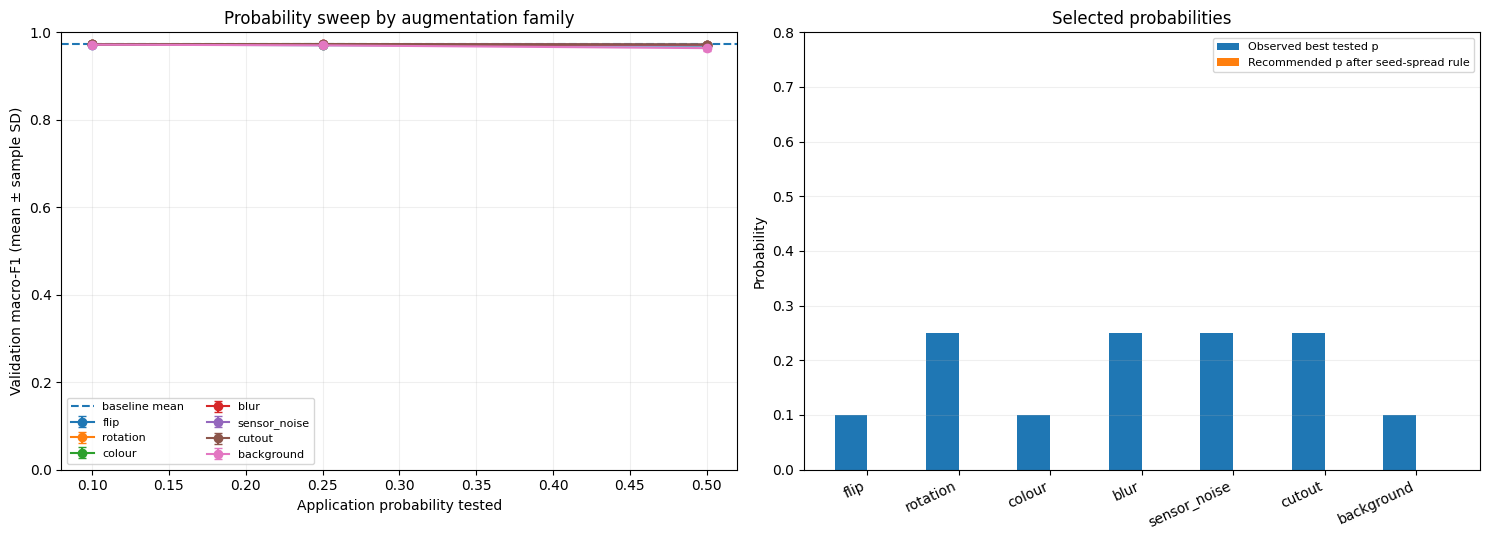

All candidates used 1 epoch(s). This is a probability screening result, not a convergence claim.
Summary: /kaggle/working/terravista_augmentation_validation_study/probability_search/probability_search_mean_std.csv
Selected probabilities: /kaggle/working/terravista_augmentation_validation_study/probability_search/best_probability_per_augmentation.csv


In [12]:
if SEARCH_COMPLETE:
    fig,axes=plt.subplots(1,2,figsize=(15,5.5))
    for family,key,description in PROBABILITY_FAMILIES:
        sub=summary_df[summary_df["family"]==family].sort_values("tested_probability")
        axes[0].errorbar(sub["tested_probability"],sub["val_macro_f1_mean"],yerr=sub["val_macro_f1_std"],marker="o",capsize=3,label=family)
    base_mean=float(summary_df.loc[summary_df["config_name"]=="baseline_all_probabilities_zero","val_macro_f1_mean"].iloc[0])
    axes[0].axhline(base_mean,linestyle="--",label="baseline mean")
    axes[0].set_xlabel("Application probability tested"); axes[0].set_ylabel("Validation macro-F1 (mean ± sample SD)")
    axes[0].set_title("Probability sweep by augmentation family"); axes[0].set_ylim(0,1); axes[0].legend(fontsize=8,ncol=2); axes[0].grid(alpha=.2)
    _x=np.arange(len(selected_probs_df))
    axes[1].bar(_x-0.18,selected_probs_df["observed_best_probability"],width=.36,label="Observed best tested p")
    axes[1].bar(_x+0.18,selected_probs_df["recommended_probability"],width=.36,label="Recommended p after seed-spread rule")
    axes[1].set_xticks(_x); axes[1].set_xticklabels(selected_probs_df["family"],rotation=25,ha="right")
    axes[1].set_ylim(0,0.8); axes[1].set_ylabel("Probability"); axes[1].set_title("Selected probabilities"); axes[1].legend(fontsize=8); axes[1].grid(axis="y",alpha=.2)
    fig.tight_layout(); fig.savefig(RUN_DIR/"augmentation_probability_sweep.png",dpi=180,bbox_inches="tight")
    if IN_NOTEBOOK: plt.show()
    plt.close(fig)

    # End-of-epoch scores are a screen; list any candidates that reached their best possible epoch.
    print(f"All candidates used {SCREEN_EPOCHS} epoch(s). This is a probability screening result, not a convergence claim.")
    print("Summary:",RUN_DIR/"probability_search_mean_std.csv")
    print("Selected probabilities:",RUN_DIR/"best_probability_per_augmentation.csv")


## Optional combined confirmation run

The selected probability for each family above was estimated while that family was tested alone. Augmentations can interact, so this optional cell checks the combined recipe using the recommended probabilities. It trains the combined configuration for 2 epochs with all three seeds and scores validation only. It is off by default to keep the main probability sweep within the Kaggle session budget.


In [13]:
RUN_COMBINED_CONFIRMATION=False
COMBINED_CONFIRMATION_EPOCHS=2
if RUN_COMBINED_CONFIRMATION:
    if not SEARCH_COMPLETE: raise RuntimeError("Complete the probability sweep and selection first.")
    combined_cfg={"name":"combined_selected_probabilities","family":"combined","tested_probability":float("nan"),**selected_probs}
    combined_rows=[]
    for seed in SEEDS:
        reset_random_seeds(seed)
        use_bg=combined_cfg["p_background"]>0
        train_loader=make_loader(TRAIN_POSITIONS,TRAIN_LABEL_IDS,train=True,seed=seed,include_background_mask=use_bg)
        val_loader=make_loader(VAL_POSITIONS,VAL_LABEL_IDS,train=False,seed=seed)
        model=build_resnet50(); optimizer=make_optimizer(model); scaler=new_grad_scaler()
        best=None
        for epoch in range(1,COMBINED_CONFIRMATION_EPOCHS+1):
            train_stats=train_one_epoch(model,train_loader,optimizer,scaler,combined_cfg)
            val=evaluate_model(model,val_loader)
            row={"seed":seed,"epoch":epoch,**train_stats,**{k:v for k,v in val.items() if k not in {"y_true","y_pred"}}}
            print(f"combined | seed={seed} | epoch={epoch}/{COMBINED_CONFIRMATION_EPOCHS} | val macro-F1={row['val_macro_f1']:.4f}")
            if best is None or row["val_macro_f1"]>best["val_macro_f1"]:
                best=row.copy()
                torch.save({"model_state_dict":{k:v.detach().cpu() for k,v in model.state_dict().items()},"class_names":CLASS_NAMES,"selected_probabilities":selected_probs,"seed":seed,"epoch":epoch,"validation_only":True},RUN_DIR/f"combined_selected_seed{seed}_best.pt")
        combined_rows.append({"seed":seed,**{k:v for k,v in best.items() if k!="seed"}})
        pd.DataFrame(combined_rows).to_csv(RUN_DIR/"combined_confirmation_seed_results_IN_PROGRESS.csv",index=False)
        del model,optimizer,scaler,train_loader,val_loader; gc.collect(); torch.cuda.empty_cache()
    combined_df=pd.DataFrame(combined_rows)
    combined_df.to_csv(RUN_DIR/"combined_confirmation_seed_results.csv",index=False)
    result={"selected_probabilities":selected_probs,"combined_val_macro_f1_mean":float(combined_df.val_macro_f1.mean()),"combined_val_macro_f1_std":float(combined_df.val_macro_f1.std(ddof=1)),"combined_val_accuracy_mean":float(combined_df.val_accuracy.mean()),"combined_val_accuracy_std":float(combined_df.val_accuracy.std(ddof=1)),"epochs":COMBINED_CONFIRMATION_EPOCHS,"seeds":SEEDS,"test_data_used":False}
    (RUN_DIR/"combined_confirmation_summary.json").write_text(json.dumps(result,indent=2))
    print(json.dumps(result,indent=2))
else:
    print("Combined confirmation is OFF. After the probability sweep, set RUN_COMBINED_CONFIRMATION=True and rerun this cell if runtime permits.")


Combined confirmation is OFF. After the probability sweep, set RUN_COMBINED_CONFIRMATION=True and rerun this cell if runtime permits.


## 10. Package the validation-only results

The ZIP excludes cache files, model weights, and any test data.

In [14]:
if SEARCH_COMPLETE:
    results_zip=BASE_OUTPUT_DIR/f"terravista_probability_tuning_results_{RUN_SIGNATURE}.zip"
    include=[]
    for p in RUN_DIR.rglob("*"):
        if not p.is_file(): continue
        if p.suffix in {".pt",".pth",".npy",".npz"}: continue
        if ".tmp" in p.name: continue
        include.append(p)
    with zipfile.ZipFile(results_zip,"w",compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
        for p in include: z.write(p,arcname=str(p.relative_to(BASE_OUTPUT_DIR)))
    print("Results ZIP:",results_zip)
    print("No test metrics, test predictions, or test confusion matrices were created.")
else:
    print("Finish the probability sweep before packaging final comparison results.")


Results ZIP: /kaggle/working/terravista_augmentation_validation_study/terravista_probability_tuning_results_dffcb6e173cf.zip
No test metrics, test predictions, or test confusion matrices were created.
